# Chapter 4 · Orthogonality and least squares

*Book 1 · Linear Algebra · Shelf I*

**Builds on:** [Chapter 3](03-solving-systems.ipynb) (solving, the condition number) and the dot
product from [Chapter 1](01-vectors-and-spaces.ipynb).
**You will:** project a vector onto a line and a plane, build an orthonormal basis by
Gram-Schmidt, fit a line through noisy points by least squares -- and see why the QR route is
safer than the textbook normal equations.

Most data systems have more equations than unknowns: a hundred measurements, two parameters.
There is no exact solution, only a best one. **Least squares** makes "best" precise, and
orthogonality is how it is computed well.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from ds_toolbox import viz

viz.use_style()
rng = np.random.default_rng(4)

## Projection

The projection of $b$ onto the direction $a$ is the closest point to $b$ on that line:
$\hat b = \frac{a \cdot b}{a \cdot a}\, a$. What is left, $b - \hat b$, is **orthogonal** to $a$ --
its dot product with $a$ is zero.

projection: [1.65 0.55] | residual . a = -0.0


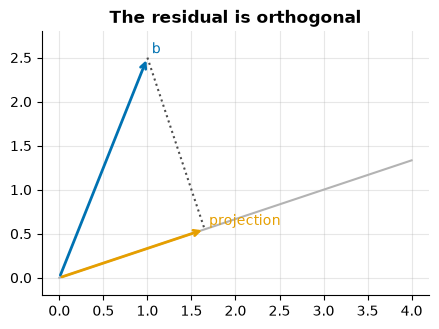

In [2]:
a = np.array([3.0, 1.0])
b = np.array([1.0, 2.5])
b_hat = (a @ b) / (a @ a) * a
print("projection:", b_hat.round(3), "| residual . a =", round((b - b_hat) @ a, 12))
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot([0, 4 * a[0] / 3], [0, 4 * a[1] / 3], color="0.7")
for vec, name, colour in [(b, "b", viz.PALETTE[0]), (b_hat, "projection", viz.PALETTE[1])]:
    ax.annotate("", xy=vec, xytext=(0, 0), arrowprops={"arrowstyle": "->", "color": colour, "lw": 2})
    ax.text(*(vec + 0.05), name, color=colour)
ax.plot(*zip(b, b_hat, strict=True), ls=":", color="0.3")
ax.set(aspect="equal", xlim=(-0.2, 4.2), ylim=(-0.2, 2.8), title="The residual is orthogonal");

## Gram-Schmidt: an orthonormal basis

Take vectors one by one; from each, subtract its projections onto the ones already kept, then
scale to length 1. The result spans the same space with mutually orthogonal unit vectors -- the
columns of $Q$ in $A = QR$.

In [3]:
def gram_schmidt(A):
    Q = np.zeros_like(A, dtype=float)
    R = np.zeros((A.shape[1], A.shape[1]))
    for j in range(A.shape[1]):
        v = A[:, j].astype(float)
        for i in range(j):
            R[i, j] = Q[:, i] @ A[:, j]
            v = v - R[i, j] * Q[:, i]
        R[j, j] = np.linalg.norm(v)
        Q[:, j] = v / R[j, j]
    return Q, R

M = rng.normal(size=(6, 3))
Q, R = gram_schmidt(M)
print("Q^T Q = I ?", np.allclose(Q.T @ Q, np.eye(3)), "| Q R = M ?", np.allclose(Q @ R, M))

Q^T Q = I ? True | Q R = M ? True


## Least squares: the best line

Fit $y \approx c_0 + c_1 x$ to 60 noisy points. In matrix form, $Xc \approx y$ with a column of
ones and a column of $x$. Least squares chooses $c$ to minimise $\lVert Xc - y \rVert^2$ -- the
projection of $y$ onto the space the columns of $X$ span.

normal equations: [0.8482 0.9568] | QR: [0.8482 0.9568] | lstsq: [0.8482 0.9568]


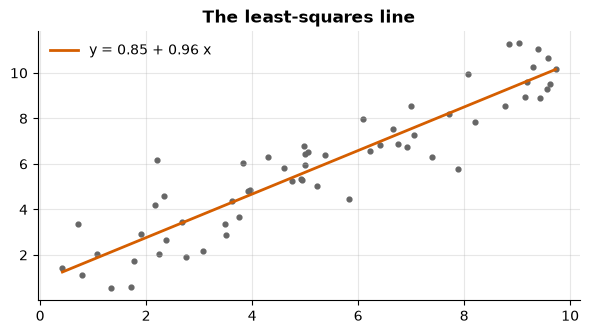

In [4]:
x = np.sort(rng.uniform(0, 10, 60))
y = 1.5 + 0.8 * x + rng.normal(0, 1.2, 60)
X = np.column_stack([np.ones_like(x), x])

c_normal = np.linalg.solve(X.T @ X, X.T @ y)          # the normal equations
Qx, Rx = np.linalg.qr(X)
c_qr = np.linalg.solve(Rx, Qx.T @ y)                   # via QR
c_lib = np.linalg.lstsq(X, y, rcond=None)[0]
print("normal equations:", c_normal.round(4), "| QR:", c_qr.round(4), "| lstsq:", c_lib.round(4))
plt.figure(figsize=(7, 3.5))
plt.scatter(x, y, s=12, color="0.4")
plt.plot(x, X @ c_qr, color=viz.PALETTE[3], lw=2, label=f"y = {c_qr[0]:.2f} + {c_qr[1]:.2f} x")
plt.legend()
plt.title("The least-squares line");

## Why QR is the safer route

The normal equations form $X^\top X$, whose condition number is the *square* of $X$'s. When the
columns of $X$ are nearly dependent -- a polynomial in $x$ of high degree, say -- squaring the
condition number costs half the digits. QR never forms $X^\top X$.

In [5]:
xs = np.linspace(0, 1, 50)
for degree in (4, 8, 12):
    V = np.vander(xs, degree + 1, increasing=True)
    coef = np.ones(degree + 1)
    target = V @ coef
    via_normal = np.linalg.solve(V.T @ V, V.T @ target)
    q, r = np.linalg.qr(V)
    via_qr = np.linalg.solve(r, q.T @ target)
    print(f"degree {degree:2d}: cond(X) {np.linalg.cond(V):8.1e} · cond(X^T X) {np.linalg.cond(V.T @ V):8.1e} · "
          f"error normal {np.abs(via_normal - coef).max():7.1e} · error QR {np.abs(via_qr - coef).max():7.1e}")

degree  4: cond(X)  6.4e+02 · cond(X^T X)  4.1e+05 · error normal 3.5e-12 · error QR 1.7e-14
degree  8: cond(X)  6.3e+05 · cond(X^T X)  3.9e+11 · error normal 1.0e-05 · error QR 4.3e-12
degree 12: cond(X)  6.8e+08 · cond(X^T X)  6.0e+17 · error normal 1.6e+00 · error QR 5.6e-08


## What to remember

- Projecting leaves an orthogonal residual; least squares is a projection.
- Gram-Schmidt builds an orthonormal basis: $A = QR$.
- Solve least squares with QR (or `lstsq`), not the normal equations.

## Exercises

1. Fit a parabola to the points above. Is the quadratic coefficient distinguishable from zero?
2. Run `gram_schmidt` on the degree-12 Vandermonde matrix. How orthogonal is the result?
3. Show that the residual of the least-squares fit is orthogonal to both columns of $X$.

**Next:** [Chapter 5 · Eigenvalues and the SVD](05-eigenvalues-and-svd.ipynb)